<a href="https://colab.research.google.com/github/hizocar/machine_learning_egei/blob/main/docs/notebooks/s07_shrinkage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 7 · Selection and Shrinkage: How Short Can the Form Be?

**So far** our poverty model uses 19 variables: 19 questions a social worker must ask, record and
verify in every household visit.

**Today's question.** Every question costs interview time, can be gamed by applicants, and must be
checked. **Which variables do we really need?** A shorter form that predicts almost as well is a
policy win.

**What is new today:** forward stepwise selection, penalised logistic regression (Ridge, LASSO,
Elastic Net), the penalty strength `C = 1/λ`, the regularisation path, and choosing the penalty by
cross-validation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

DATA_URL = "https://raw.githubusercontent.com/hizocar/machine_learning_egei/main/docs/data/casen_households.csv"
LOCAL = Path("../data/casen_households.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else DATA_URL)

NUM = ["head_age", "head_schooling_years", "household_size"]
HOURS = ["head_weekly_hours"]
CAT = ["region", "area", "head_sex", "head_activity", "head_job_type", "health_insurance",
       "head_nationality", "head_indigenous", "has_children", "has_elderly", "household_type",
       "housing_tenure", "dwelling_type", "overcrowding", "head_education"]
RAW = NUM + HOURS + CAT          # the 19 questions on the form

X, y = df[RAW], df["poor"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(X_train.shape, f"poor share {y_train.mean():.3f}")

(11250, 19) poor share 0.231


## 1. The preprocessing, as a function of which questions we keep

Same rules as Session 5, but now the list of columns changes from model to model, so we wrap the
`ColumnTransformer` in a small function.

In [2]:
def preprocessor(cols):
    """The Session 5 preprocessing, restricted to the columns in `cols`."""
    num, hours, cat = [c for c in cols if c in NUM], [c for c in cols if c in HOURS], [c for c in cols if c in CAT]
    parts = []
    if num:
        parts.append(("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num))
    if hours:
        parts.append(("hours", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), hours))
    if cat:
        parts.append(("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                                           OneHotEncoder(handle_unknown="ignore")), cat))
    return ColumnTransformer(parts)


def cv_auc(model, cols):
    s = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return s.mean(), s.std()


full = Pipeline([("pre", preprocessor(RAW)), ("clf", LogisticRegression(max_iter=3000))])
auc_full, sd_full = cv_auc(full, RAW)
print(f"Session 5 model, all 19 questions: CV AUC {auc_full:.3f} ± {sd_full:.3f}")

Session 5 model, all 19 questions: CV AUC 0.781 ± 0.009


## 2. Forward stepwise selection: build the form one question at a time

Best subset selection would try every possible form: with 19 questions that is 2¹⁹ ≈ 524,000
models. **Forward stepwise** is the greedy shortcut: start with no questions; at each step add the
one question that raises the cross-validated AUC the most.

We select **questions** (raw variables), not dummy columns: a form cannot ask "region = Maule?"
without asking the region. scikit-learn's `SequentialFeatureSelector` works on the columns of the
final matrix (the dummies), so we write the loop ourselves, with one pipeline per candidate set.
It takes about a minute.

In [3]:
chosen, path = [], []
for step in range(10):
    trials = []
    for v in RAW:
        if v in chosen:
            continue
        model = Pipeline([("pre", preprocessor(chosen + [v])), ("clf", LogisticRegression(max_iter=3000))])
        trials.append((*cv_auc(model, chosen + [v]), v))
    auc, sd, best_v = max(trials)
    chosen.append(best_v)
    path.append({"questions": len(chosen), "added": best_v, "cv_auc": auc, "sd": sd})
forward = pd.DataFrame(path)
# The short form: the fewest questions whose CV AUC is within 0.01 of the full form.
n_short = int(forward.loc[forward["cv_auc"] >= auc_full - 0.01, "questions"].min())
print(f"Short form: {n_short} questions")
forward.round(3)

Short form: 8 questions


,questions,added,cv_auc,sd
0,1,head_job_type,0.657,0.009
1,2,head_age,0.702,0.013
2,3,head_education,0.726,0.010
3,4,household_type,0.744,0.011
4,5,has_children,0.757,0.009
5,6,housing_tenure,0.766,0.010
6,7,region,0.771,0.009
7,8,head_weekly_hours,0.774,0.009
8,9,health_insurance,0.778,0.010
9,10,overcrowding,0.779,0.010


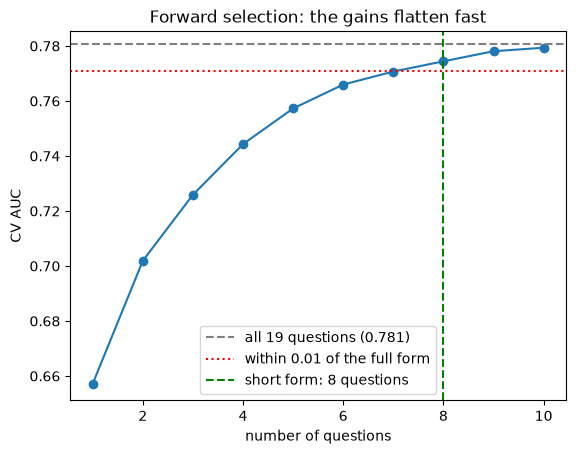

In [4]:
plt.plot(forward["questions"], forward["cv_auc"], marker="o")
plt.axhline(auc_full, ls="--", c="grey", label=f"all 19 questions ({auc_full:.3f})")
plt.axhline(auc_full - 0.01, ls=":", c="red", label="within 0.01 of the full form")
plt.axvline(n_short, ls="--", c="green", label=f"short form: {n_short} questions")
plt.xlabel("number of questions"); plt.ylabel("CV AUC"); plt.legend()
plt.title("Forward selection: the gains flatten fast");

**Eight questions reach 0.774**, within 0.01 of the full 19-question form (0.781). Seven reach
0.771, a hair below the line: the 0.01 is a convention, not a law, so report the curve and not only the
cut-off. The order is informative too: `head_schooling_years` is never chosen early because `head_education` already
carries almost the same information. Greedy selection picks one of two correlated variables and
ignores the other. That says *redundant*, not *irrelevant*.

## 3. Penalised regression: shrink instead of choosing

Selection is all-or-nothing. **Shrinkage** keeps every variable but adds a price for large
coefficients to the quantity the model minimises:

$$\text{log-loss}(\beta) + \lambda \cdot \text{penalty}(\beta)$$

| Method | Penalty | Effect |
|---|---|---|
| **Ridge** (L2) | $\sum_j \beta_j^2$ | shrinks all coefficients towards 0, none exactly 0 |
| **LASSO** (L1) | $\sum_j \lvert\beta_j\rvert$ | shrinks, and sets some coefficients **exactly** to 0 |
| **Elastic Net** | a mix of both | sparse like LASSO, more stable with correlated variables |

In scikit-learn the strength is `C = 1/λ`: **small C = strong penalty**. Because the penalty
compares coefficients with each other, all variables must be on the same scale, which is why the
`StandardScaler` stays in the pipeline.

> ⚠️ scikit-learn's `LogisticRegression()` is **already Ridge with C = 1** by default. The
> Session 5 model was slightly penalised all along. Econometrics software (Stata, statsmodels)
> does not penalise by default.

### A version trap

scikit-learn 1.8 changed how you ask for LASSO: `penalty="l1"` became `l1_ratio=1`. Older versions,
still common on Colab, silently **ignore** `l1_ratio` unless `penalty="elasticnet"`, and so fit a
Ridge without telling you. This helper works on both:

In [5]:
NEW_API = tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 8)
print("scikit-learn", sklearn.__version__, "| new penalty API:", NEW_API)


def penalised_logit(C, l1_ratio):
    """l1_ratio = 0 -> Ridge, 1 -> LASSO, in between -> Elastic Net."""
    solver = "liblinear" if l1_ratio in (0, 1) else "saga"
    if NEW_API:
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver=solver, max_iter=5000, random_state=0)
    penalty = {0: "l2", 1: "l1"}.get(l1_ratio, "elasticnet")
    extra = {"l1_ratio": l1_ratio} if penalty == "elasticnet" else {}
    return LogisticRegression(C=C, penalty=penalty, solver=solver, max_iter=5000, random_state=0, **extra)

scikit-learn 1.9.1 | new penalty API: True


## 4. The LASSO path: from no variables to all of them

We fit the LASSO for 40 values of C, from a very strong penalty (C = 0.001) to a weak one (C = 10),
and record the coefficients, the CV AUC, and how many **questions** still have at least one
non-zero coefficient.

In [6]:
def question_of(feature):
    body = feature.split("__", 1)[1]
    return next(v for v in RAW if body == v or body.startswith(v + "_"))


Cs = np.logspace(-3, 1, 40)
rows, coefs = [], []
for C in Cs:
    model = Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(C, 1))])
    auc, sd = cv_auc(model, RAW)
    model.fit(X_train, y_train)
    names = model.named_steps["pre"].get_feature_names_out()
    b = model.named_steps["clf"].coef_[0]
    used = {question_of(n) for n, v in zip(names, b) if v != 0}
    rows.append({"C": C, "cv_auc": auc, "sd": sd, "se": sd / np.sqrt(cv.get_n_splits()),
                 "non_zero": int((b != 0).sum()), "questions": len(used)})
    coefs.append(b)
lasso = pd.DataFrame(rows)
coefs = pd.DataFrame(coefs, columns=names)

best = lasso["cv_auc"].idxmax()
# 1-SE rule: the most penalised model whose CV AUC is within one standard error of the best,
# where SE = fold sd / sqrt(5).
one_se = lasso.index[lasso["cv_auc"] >= lasso.loc[best, "cv_auc"] - lasso.loc[best, "se"]].min()
lasso.loc[[best, one_se]].round(4).assign(choice=["CV-best", "1-SE rule"])

,C,cv_auc,sd,se,non_zero,questions,choice
29,0.9427,0.7810,0.0094,0.0042,60,18,CV-best
18,0.0702,0.7774,0.0094,0.0042,35,18,1-SE rule


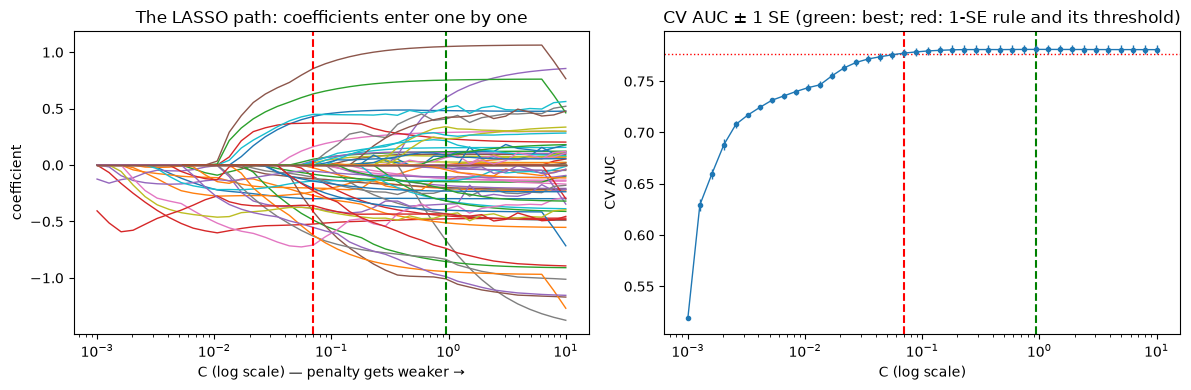

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(Cs, coefs.values, lw=1)
ax[0].set_xscale("log"); ax[0].set_xlabel("C (log scale) — penalty gets weaker →"); ax[0].set_ylabel("coefficient")
ax[0].set_title("The LASSO path: coefficients enter one by one")
for i, c in [(best, "green"), (one_se, "red")]:
    ax[0].axvline(Cs[i], c=c, ls="--"); ax[1].axvline(Cs[i], c=c, ls="--")
ax[1].errorbar(Cs, lasso["cv_auc"], yerr=lasso["se"], marker=".", lw=1)
ax[1].axhline(lasso.loc[best, "cv_auc"] - lasso.loc[best, "se"], c="red", ls=":", lw=1)
ax[1].set_xscale("log"); ax[1].set_xlabel("C (log scale)"); ax[1].set_ylabel("CV AUC")
ax[1].set_title("CV AUC ± 1 SE (green: best; red: 1-SE rule and its threshold)")
plt.tight_layout()

- The **CV-best** LASSO matches the full model (AUC 0.781) while zeroing 16 of 76 coefficients.
- The **1-SE rule** picks the simplest (most penalised) model whose CV AUC is within one standard
  error of the best, where SE = fold sd / √5 ≈ 0.004. Differences smaller than that are noise. It
  keeps **35 coefficients** at CV AUC 0.777.
- But look at the `questions` column: those 35 coefficients still come from **18 of the 19
  questions**. LASSO drops *dummies*, not *questions*. It may keep `region = La Araucanía` and drop
  every other region, and the form still has to ask the region.

In [8]:
kept = coefs.loc[one_se]
kept = kept[kept != 0].sort_values()
kept.round(3).to_frame("coefficient (1-SE LASSO)")

,coefficient (1-SE LASSO)
cat__has_children_no,-0.709
cat__health_insurance_isapre,-0.630
cat__household_type_extended_two_parents,-0.622
cat__head_education_6_tertiary_complete,-0.553
hours__head_weekly_hours,-0.523
cat__head_job_type_public_sector,-0.488
cat__health_insurance_armed_forces,-0.415
cat__head_activity_employed,-0.384
cat__housing_tenure_owned,-0.382
cat__overcrowding_0_none,-0.359


## 5. Ridge vs LASSO vs Elastic Net on the full form

In [9]:
grid = np.logspace(-3, 1, 9)
compare = []
for label, l1_ratio in [("Ridge", 0), ("LASSO", 1), ("Elastic Net (0.5)", 0.5)]:
    scores = [(cv_auc(Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(C, l1_ratio))]), RAW), C) for C in grid]
    (auc, sd), C = max(scores)
    compare.append({"method": label, "best C": C, "cv_auc": round(auc, 3), "sd": round(sd, 3)})
pd.DataFrame(compare)

,method,best C,cv_auc,sd
0,Ridge,0.316228,0.781,0.009
1,LASSO,1.000000,0.781,0.009
2,Elastic Net (0.5),1.000000,0.781,0.009


All three tie at 0.781. With 11,250 households and 76 columns, the unpenalised logit is
already stable, so shrinkage cannot buy much accuracy here. Its value on this data is
**sparsity and interpretability**, not AUC.

## 6. When does shrinkage pay off? When data is scarce

Imagine a pilot survey in one province: a few hundred households, the same 76 columns. We train
on random subsamples of the training set and evaluate on the (full) test set.

In [10]:
def test_auc(model, Xs, ys):
    return roc_auc_score(y_test, model.fit(Xs, ys).predict_proba(X_test)[:, 1])


def best_C(l1_ratio, Xs, ys):
    return max(grid, key=lambda C: cross_val_score(
        Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(C, l1_ratio))]),
        Xs, ys, cv=cv, scoring="roc_auc").mean())


small = []
for n in [300, 1000, len(X_train)]:
    for rep in range(5 if n < len(X_train) else 1):          # the full training set has only one "sample"
        Xs = X_train.sample(n, random_state=rep); ys = y_train.loc[Xs.index]
        small.append({"n": n, "rep": rep,
            "no penalty": test_auc(Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(1e4, 0))]), Xs, ys),
            "Ridge (CV)": test_auc(Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(best_C(0, Xs, ys), 0))]), Xs, ys),
            "LASSO (CV)": test_auc(Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(best_C(1, Xs, ys), 1))]), Xs, ys)})
pd.DataFrame(small).groupby("n")[["no penalty", "Ridge (CV)", "LASSO (CV)"]].mean().round(3)

,no penalty,Ridge (CV),LASSO (CV)
n,,,
300,0.686,0.733,0.725
1000,0.754,0.782,0.779
11250,0.794,0.795,0.795


With 300 households the unpenalised logit has 76 coefficients to estimate from about 70 poor
households. It fits the noise, and the penalty cuts that variance. With all the data the gap disappears.
This is the bias–variance trade-off from Session 3 again: the penalty adds a little bias to remove a
lot of variance, and that trade is worth making when variance is the bigger problem.

## 7. The test set, once

In [11]:
short_form = chosen[:n_short]
final = [  # (name, model, columns it reads, questions the form must ask)
    ("Full form (Session 5)", Pipeline([("pre", preprocessor(RAW)), ("clf", LogisticRegression(max_iter=3000))]),
     RAW, len(RAW)),
    ("Short form (forward selection)", Pipeline([("pre", preprocessor(short_form)), ("clf", LogisticRegression(max_iter=3000))]),
     short_form, len(short_form)),
    ("LASSO, 1-SE rule", Pipeline([("pre", preprocessor(RAW)), ("clf", penalised_logit(Cs[one_se], 1))]),
     RAW, lasso.loc[one_se, "questions"]),
]
pd.DataFrame([{"model": name, "questions": q,
               "test AUC": round(roc_auc_score(y_test, m.fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]), 3)}
              for name, m, cols, q in final])

,model,questions,test AUC
0,Full form (Session 5),19,0.794
1,Short form (forward selection),8,0.786
2,"LASSO, 1-SE rule",18,0.795


The short form gives up a little AUC and saves 11 questions per household visit. Whether that
trade is worth it depends on the cost of a visit, the risk of manipulation and the cost of each
error. That is a policy decision, but now it can be made with numbers on the table.

## 8. With your assistant: debugging, not guessing

```text
I fit LogisticRegression(l1_ratio=1, solver="liblinear", C=0.03) inside a Pipeline on Colab,
expecting a LASSO, but none of the 76 coefficients is exactly zero. My scikit-learn version is
(paste sklearn.__version__). Diagnose the cause. Show me the evidence: which line of the
documentation for MY version explains it, and a two-line check I can run to confirm.
```
Check: does it ask for (or use) your version before answering? Does it give you a check you can
run (count `coef_ == 0`), or only a confident explanation?

## 9. Exercises

1. Remove the `StandardScaler` from the numeric pipeline and refit the 1-SE LASSO. Which
   coefficients change most, and why does the penalty now treat `head_age` unfairly?
2. Continue the forward selection to all 19 questions. At which step does the CV AUC stop changing
   in the third decimal? Does that agree with the LASSO's ranking of variables?
3. Your short form keeps `region`. Refit it without `region`: how much CV AUC do you lose? Write
   three sentences for a ministry explaining one advantage and one risk of a region-blind targeting rule.